In [1]:
from pathlib import Path
import sys
import cv2
import numpy as np

# Tìm thư mục gốc của project
root = Path.cwd()

while not ((root / "data" / "raw").is_dir()
           and (root / "source" / "preprocessing.py").is_file()):
    if root == root.parent:
        raise FileNotFoundError("Project root not found")
    root = root.parent

# Đường dẫn dùng chung cho các cell, bao gồm cell lưu hình.
ROOT = root
(ROOT / "results" / "figures").mkdir(parents=True, exist_ok=True)

# Cho phép import source khi kernel chạy từ source/experiments.
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

paths = sorted((root / "data" / "raw").rglob("*.png"))
if not paths:
    raise FileNotFoundError(f"Không tìm thấy ảnh PNG trong {root / 'data' / 'raw'}")

opaque_count = 0
transparent_count = 0

for path in paths:
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if image is None:
        raise ValueError(f"OpenCV không đọc được ảnh: {path}")
    if image.ndim != 3 or image.shape[2] not in (3, 4):
        raise ValueError(f"Ảnh không phải BGR/BGRA: {path}, shape={image.shape}")
    # IMREAD_UNCHANGED giữ Alpha; BGR không có Alpha được coi là opaque.
    alpha = image[:, :, 3] if image.shape[2] == 4 else np.full(image.shape[:2], 255, np.uint8)

    if np.all(alpha == 255):
        opaque_count += 1
    else:
        transparent_count += 1

print("Total images:", len(paths))
print("Opaque images:", opaque_count)
print("Images with transparency:", transparent_count)
print("OpenCV:", cv2.__version__)
print("Last image shape/channels:", image.shape)
assert len(paths) == 1283 and opaque_count == 1283 and transparent_count == 0


Total images: 1283
Opaque images: 1283
Images with transparency: 0
OpenCV: 4.14.0
Last image shape/channels: (300, 300, 4)


In [2]:
from source.preprocessing import build_preprocessing
import torch
transform = build_preprocessing((64, 64))

image = cv2.imread(str(paths[0]), cv2.IMREAD_UNCHANGED)
if image is None:
    raise ValueError(f"OpenCV không đọc được ảnh: {paths[0]}")
tensor = transform(image)

assert tensor.shape == (3, 64, 64)
assert tensor.dtype == torch.float32
assert tensor.min() >= 0
assert tensor.max() <= 1
assert torch.isfinite(tensor).all()

print("Preprocessing: PASS")
assert tensor.is_contiguous()
assert torch.equal(tensor, transform(image))
assert build_preprocessing((32, 64))(image).shape == (3, 32, 64)
print("Shape/dtype/range:", tensor.shape, tensor.dtype, tensor.min().item(), tensor.max().item())


Preprocessing: PASS
Shape/dtype/range: torch.Size([3, 64, 64]) torch.float32 0.0 1.0


### Kiểm tra hợp đồng OpenCV
NumPy uint8 BGR/BGRA → RGB tensor CHW float32 [0,1]. Màu chỉ đổi một lần trong
preprocessing; resize dùng (width,height). Alpha khác 255 được ghép lên nền trắng,
giữ chính sách Pillow cũ. Dataset/Loader vẫn TODO, các kiểm tra dưới đây chỉ kiểm tra preprocessing.


Lượt refactor: các code cell đã chạy tuần tự bằng Python exec (stdout thật được lưu).
Jupyter kernel bị sandbox chặn socket; execution_count để null, xem metadata.verification.
Có thể Run All trong Jupyter trên máy để ghi execution count và hiển thị hình inline.

In [3]:
# Pixel đỏ trong BGR phải trở thành kênh R=1, B=0.
red = np.array([[[0, 0, 255]]], dtype=np.uint8)
red_bgra = np.concatenate([red, np.full((1, 1, 1), 255, np.uint8)], axis=2)
for sample in (red, red_bgra):
    assert torch.equal(build_preprocessing((1, 1))(sample)[:, 0, 0], torch.tensor([1., 0., 0.]))
for value in (0, 255):
    sample = np.full((4, 7, 3), value, dtype=np.uint8)
    assert torch.all(transform(sample) == value / 255)
transparent = np.array([[[0, 0, 255, 0]]], dtype=np.uint8)
assert torch.all(transform(transparent) == 1)  # nền trắng
for invalid in (None, np.zeros((3, 3), dtype=np.uint8)):
    try:
        transform(invalid)
    except (ValueError, TypeError) as exc:
        print(type(exc).__name__, str(exc))
    else:
        raise AssertionError("Ảnh không hợp lệ phải báo lỗi")
print("BGR/BGRA, black/white, alpha và invalid input: PASS")

TypeError image must be a NumPy uint8 BGR/BGRA array, not None or PIL
ValueError image must be non-empty HWC with 3 BGR or 4 BGRA channels
BGR/BGRA, black/white, alpha và invalid input: PASS


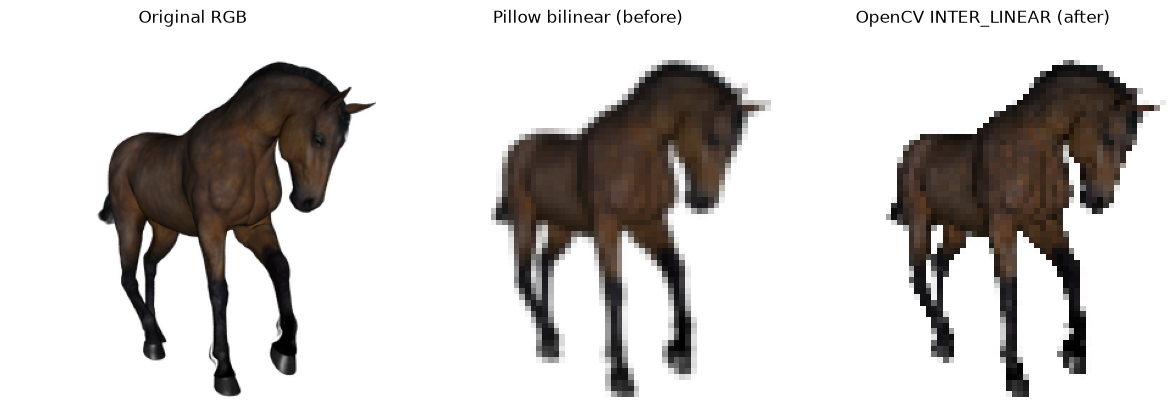

Mean absolute pixel difference: 0.02067791484296322


In [4]:
import matplotlib.pyplot as plt
from PIL import Image as PillowImage  # Chỉ để tái hiện baseline trước refactor.

# Ảnh gốc opaque đã được kiểm tra ở trên; đổi BGRA/BGR sang RGB chỉ để hiển thị.
original_rgb = cv2.cvtColor(image, cv2.COLOR_BGRA2RGB if image.shape[2] == 4 else cv2.COLOR_BGR2RGB)
with PillowImage.open(paths[0]) as old_image:
    rgba = old_image.convert("RGBA")
    white = PillowImage.new("RGBA", rgba.size, (255, 255, 255, 255))
    old_rgb = PillowImage.alpha_composite(white, rgba).convert("RGB")
    pillow_result = np.asarray(old_rgb.resize((64, 64), PillowImage.Resampling.BILINEAR), dtype=np.float32) / 255
# Tensor mới đã là RGB: chỉ CHW -> HWC, không cvtColor lần nữa.
opencv_result = tensor.permute(1, 2, 0).numpy()
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, pixels, title in zip(axes, [original_rgb, pillow_result, opencv_result],
                            ["Original RGB", "Pillow bilinear (before)", "OpenCV INTER_LINEAR (after)"]):
    ax.imshow(pixels)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
fig.savefig(ROOT / "results/figures/preprocessing_opencv_comparison.png", dpi=150)
plt.show()
print("Mean absolute pixel difference:", float(np.abs(pillow_result - opencv_result).mean()))

In [5]:
from source.config import CONFIG
from source.dataset import HorseHumanDataset
from source.preprocessing import build_preprocessing

transform = build_preprocessing(CONFIG.image_size)

train_dataset = HorseHumanDataset(
    csv_path=CONFIG.splits_dir / "train.csv",
    transform=transform
)

print("Train samples:", len(train_dataset))

Train samples: 845


In [6]:
image, target = train_dataset[0]

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Image min:", image.min().item())
print("Image max:", image.max().item())

print("Target:", target)
print("Target shape:", target.shape)
print("Target dtype:", target.dtype)

Image shape: torch.Size([3, 64, 64])
Image dtype: torch.float32
Image min: 0.07450980693101883
Image max: 1.0
Target: tensor([0.])
Target shape: torch.Size([1])
Target dtype: torch.float32


In [7]:
assert len(train_dataset) == 845

assert image.shape == (3, 64, 64)
assert image.dtype == torch.float32
assert image.min() >= 0
assert image.max() <= 1
assert torch.isfinite(image).all()

assert target.shape == (1,)
assert target.dtype == torch.float32
assert target.item() in [0, 1]

print("Custom Dataset: PASS")

Custom Dataset: PASS


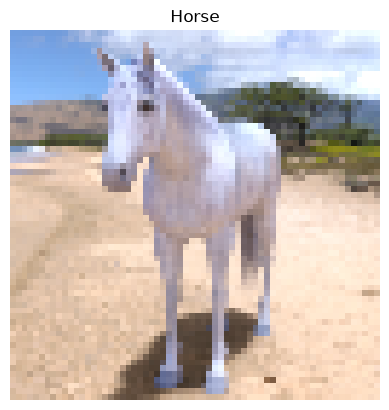

In [8]:
import matplotlib.pyplot as plt

class_names = {
    0: "Horse",
    1: "Human"
}

image, target = train_dataset[0]

plt.imshow(image.permute(1, 2, 0))
plt.title(class_names[int(target.item())])
plt.axis("off")
plt.show()

In [13]:
from source.dataset import build_loaders
from source.config import CONFIG

loaders = build_loaders(CONFIG)

for name, loader in loaders.items():
    images, targets = next(iter(loaders["train"]))

    print("Images:", images.shape)
    print("Targets:", targets.shape)

print("Images shape:", images.shape)
print("Images dtype:", images.dtype)

print("Targets shape:", targets.shape)
print("Targets dtype:", targets.dtype)

print("Min pixel:", images.min().item())
print("Max pixel:", images.max().item())

assert images.shape == (32, 3, 64, 64)
assert targets.shape == (32, 1)

assert images.dtype == torch.float32
assert targets.dtype == torch.float32

assert images.min() >= 0
assert images.max() <= 1
assert torch.isfinite(images).all()

print("Mini-batch: PASS")

for name, loader in loaders.items():
    print(
        f"{name}: "
        f"Samples={len(loader.dataset)}, "
        f"Batches={len(loader)}"
    )

Images: torch.Size([32, 3, 64, 64])
Targets: torch.Size([32, 1])
Images: torch.Size([32, 3, 64, 64])
Targets: torch.Size([32, 1])
Images: torch.Size([32, 3, 64, 64])
Targets: torch.Size([32, 1])
Images shape: torch.Size([32, 3, 64, 64])
Images dtype: torch.float32
Targets shape: torch.Size([32, 1])
Targets dtype: torch.float32
Min pixel: 0.0
Max pixel: 1.0
Mini-batch: PASS
train: Samples=845, Batches=27
val: Samples=182, Batches=6
test: Samples=256, Batches=8


In [14]:
from torch.utils.data import (
    RandomSampler,
    SequentialSampler
)

assert isinstance(
    loaders["train"].sampler,
    RandomSampler
)

assert isinstance(
    loaders["val"].sampler,
    SequentialSampler
)

assert isinstance(
    loaders["test"].sampler,
    SequentialSampler
)

print("Sampler: PASS")

Sampler: PASS


In [15]:
for name, loader in loaders.items():

    total_samples = 0

    for images, targets in loader:

        batch_size = images.shape[0]

        assert images.shape == (batch_size, 3, 64, 64)
        assert targets.shape == (batch_size, 1)

        assert images.dtype == torch.float32
        assert targets.dtype == torch.float32

        assert images.min() >= 0
        assert images.max() <= 1
        assert torch.isfinite(images).all()

        assert ((targets == 0) | (targets == 1)).all()

        total_samples += batch_size

    assert total_samples == len(loader.dataset)

    print(
        f"{name}: "
        f"Total={total_samples}, "
        f"Last batch={batch_size} - PASS"
    )

train: Total=845, Last batch=13 - PASS
val: Total=182, Last batch=22 - PASS
test: Total=256, Last batch=32 - PASS


In [16]:
loaders_a = build_loaders(CONFIG)
loaders_b = build_loaders(CONFIG)

indices_a = list(iter(loaders_a["train"].sampler))
indices_b = list(iter(loaders_b["train"].sampler))

assert indices_a == indices_b

assert sorted(indices_a) == list(range(845))

print("Reproducible shuffle: PASS")

Reproducible shuffle: PASS
